# Cognitive predictors of rule use: COSMOS → A998 multiplication

**Question.** Do COSMOS factors at age 6-7 predict accuracy on the **zero rule** (n×0 = 0) in A998 two years later,
beyond ordinary multiplication facts? And is that specific to the zero rule, or true of rule facts in general (the
**one rule**, n×1 = n)? **Hypothesis:** working memory (WM) and reasoning (matrices) predict the zero rule.

**Design** (DECISIONS #50-#62)
* Predictors: COSMOS 2023-24 (PRE Nov / POST May) rebuilt in gold format, percentile vs the 2024-25 norm, as probit
  scores (1 unit = 1 norm SD); plus a combined PRE+POST score. 7 factors: processing speed is excluded.
* Outcomes: A998 multiplication 2024-25 / 2025-26, any country, 1.2 s fast-wrong rule applied (#7). Fact types:
  0-facts, 1-facts, retrieval (both operands 2-9). 0-facts only exist at age 9 (T3), so the zero rule is 7y → age 9.
* Main ("specific") model: binomial GLM, rule-fact correct / total ~ factor + own retrieval accuracy + country; SEs
  clustered by COSMOS classroom; Holm within each outcome. Effects are odds ratios (OR) per SD of the factor.

**How to read this notebook**

| § | Question | Figure |
|---|---|---|
| 1 | Who is in the data? | |
| 2 | How are the COSMOS scores built (incl. PRE+POST)? | |
| 3 | **Do the factors predict the zero rule?** | **Figure 1**: all factors × 4 outcomes, PRE vs POST |
| 4 | **Is it specific to the zero rule?** | **Figure 2**: zero rule vs one rule in a 21k cohort |
| 5 | WM or reasoning? | |
| 6 | Robustness: trial level, other outcomes, Mexico, no fast-wrong filter | |
| 7 | **Selection bias** | **Figure 3**: who is analysed + estimate under each correction |
| 8 | Conclusions | |

The first code cell holds every setting and helper; the rest only use them. Plots are saved to `analysis/plots/`.
In every forest plot: dot = OR per SD with 95% CI, grey bands = effect-size zones (negligible / small / medium /
large), coloured dashed lines = minimum detectable OR at 90% power, * = Holm p < .05.

In [1]:
import logging, sys, warnings
from pathlib import Path
import matplotlib.pyplot as plt, numpy as np, pandas as pd, statsmodels.api as sm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import norm
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
from cached_query import cached_query
from paired_stats import holm
from plot_style import C_ONE, C_ZERO, FONT_MED, paint_it_black, set_style
Q, CACHE, PLOTS = ROOT / "queries", ROOT / "cache", ROOT / "analysis" / "plots"; PLOTS.mkdir(exist_ok=True)
set_style()
for noisy in ("fontTools", "matplotlib.font_manager"):
    logging.getLogger(noisy).setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*Perfect separation.*")
warnings.filterwarnings("ignore", message=".*cov_type not fully supported with var_weights.*")  # IPW CIs: bootstrap
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

FACTORS = ["working_memory", "reasoning", "execution_speed",          # processing speed excluded
           "number_knowledge", "magnitude_comparison", "numeric_line", "arithmetic_fluency"]
LABEL = dict(zip(FACTORS, ["Working memory", "Reasoning (matrices)", "Execution speed",
                           "Number knowledge", "Magnitude comparison", "Number line", "Arithmetic fluency"]))
HYP, PHASES, MIN_RETR = ["working_memory", "reasoning"], ["pre", "post"], 5   # MIN_RETR: retrieval trials for the control
PH3 = PHASES + ["comb"]
WINDOWS = {"6y → age 8": (6, 8), "7y → age 8": (7, 8), "7y → age 9": (7, 9)}
W9 = "7y → age 9"
OUTCOMES = [  # (label, window, fact type, retrieval control)
    ("0-rule, age 9 (specific)", W9, "zero", True), ("0-rule, age 9 (raw)", W9, "zero", False),
    ("1-rule, age 9 (specific)", W9, "one", True), ("1-rule, age 8, 7y cohort (specific)", "7y → age 8", "one", True),
    ("1-rule, age 8, 6y cohort (specific)", "6y → age 8", "one", True), ("Retrieval, age 9 (reference)", W9, "retrieval", False),
    ("Retrieval, age 8, 6y cohort (reference)", "6y → age 8", "retrieval", False)]
OUT_ORDER = [o[0] for o in OUTCOMES]
PANELS = [OUT_ORDER[i] for i in (0, 2, 3, 5)]
PCOL = dict(zip(PANELS, [C_ZERO, C_ONE, C_ONE, "#6E6E6E"]))
# Effect-size zones: Cohen's r .1/.3/.5 through the latent logistic model, OR = exp(r·(π/√3)/√(1−r²)).
_r2or = lambda r: float(np.exp(r * (np.pi / np.sqrt(3)) / np.sqrt(1 - r * r)))
EFFECT_SIZES = {"small": _r2or(.1), "medium": _r2or(.3), "large": _r2or(.5)}             # 1.20, 1.77, 2.85
ZONE_COL = {"small": "#F1F1F1", "medium": "#E2E2E2", "large": "#D0D0D0"}
Z90 = norm.ppf(.975) + norm.ppf(.90)                                                     # MDE = exp(Z90·SE)
YPOS = {f: i for i, f in enumerate(FACTORS[::-1])}
DASH, DOT = (0, (5, 2)), (0, (1.5, 1.5))                                                 # MDE line styles PRE / POST
ZONE_HANDLES = [Patch(facecolor="white", edgecolor="#BBBBBB", label="negligible (0.83-1.20)"),
                Patch(facecolor=ZONE_COL["small"], label="small (1.20-1.77)"),
                Patch(facecolor=ZONE_COL["medium"], label="medium (1.77-2.85)"), Patch(facecolor=ZONE_COL["large"], label="large (> 2.85)")]
mline = lambda ls_, label: Line2D([], [], color="#444444", lw=1.8, ls=ls_, label=label)


# ---------- helpers: data ----------
def set_marker(sql, marker, old, new):
    """Replace `old` by `new` only on the lines carrying `marker` (repo convention: -- {NAME} markers in the .sql)."""
    return "\n".join(l.replace(old, new) if marker in l else l for l in sql.split("\n"))
def add_z(g):
    """Probit of the norm percentile (clipped to stay finite; 1 unit = 1 norm SD) + COSMOS measurement pattern."""
    for f in FACTORS:
        for ph in PHASES:
            g[f"z_{f}_{ph}"] = norm.ppf((g[f"{f}_{ph}_percentile"] / 100).clip(.005, .995))
    g["pat_pre_only"] = (g.pre_answered_at.notna() & g.post_answered_at.isna()).astype(float)
    g["pat_post_only"] = (g.pre_answered_at.isna() & g.post_answered_at.notna()).astype(float)
    return g
def add_comb(g, r):
    """Combined PRE+POST score (#59): (z_pre + z_post) / sqrt(2(1 + r)) with both rounds, else the round that exists.
    r = PRE-POST correlation in the 2024-25 norm (same factor and course age), so both branches have unit variance in
    the norm: 1 unit is still 1 norm SD, the two-round score just carries less measurement error."""
    for f in FACTORS:
        pre, post, rr = g[f"z_{f}_pre"], g[f"z_{f}_post"], g.cosmos_course_age.map(lambda a: r[(f, a)])
        g[f"z_{f}_comb"] = np.where(pre.notna() & post.notna(), (pre + post) / np.sqrt(2 * (1 + rr)), pre.fillna(post))
    return g
def add_retr(st, by=None):
    """Own retrieval accuracy as empirical logit, z-scored (within `by` if given): the control of the specific model."""
    st["retr_logit"] = np.log((st.k_retrieval + .5) / (st.n_retrieval - st.k_retrieval + .5))
    zf = lambda s: (s - s.mean()) / s.std()
    st["retr_logit_z"] = st.groupby(by).retr_logit.transform(zf) if by else zf(st.retr_logit)
    return st
def make_stud(tr):
    """One row per student × window: n / correct / copy errors per fact type + COSMOS scores."""
    tr = tr.dropna(subset=["window"])
    agg = (tr.groupby(["window", "student_uuid", "type"])
           .agg(n=("correct", "size"), k=("correct", "sum"), copy=("copy_error", "sum")).unstack("type"))
    agg.columns = [f"{m}_{t}" for m, t in agg.columns]
    meta = (tr.groupby(["window", "student_uuid"])
            .agg(a998_country=("a998_country", "first"), a998_classroom=("a998_classroom_uuid", "first")).reset_index())
    st = add_retr(agg.fillna(0).reset_index().merge(meta, on=["window", "student_uuid"]).merge(gold, on="student_uuid"), by="window")
    for t, c in (("zero", "acc_zero"), ("one", "acc_one"), ("retrieval", "acc_retr")):
        st[c] = st[f"k_{t}"] / st[f"n_{t}"].replace(0, np.nan)
    return st


# ---------- helpers: models ----------
kn = lambda d, ft: np.column_stack([d[f"k_{ft}"], d[f"n_{ft}"] - d[f"k_{ft}"]])          # binomial (successes, failures)
ctry_dummies = lambda c: pd.get_dummies(c.where(c.map(c.value_counts()) >= 15, "other"), prefix="c", drop_first=True, dtype=float)
def design(d, z, control, extra=(), fe=None):
    """const + factor (+ retrieval control) (+ extra columns, skipped when constant in d or within the fixed-effect
    groups) + country dummies (levels < 15 students merged) -- or classroom fixed effects when fe names a column."""
    X = pd.DataFrame({"z": d[z]}, index=d.index)
    if control:
        X["retr"] = d["retr_logit_z"]
    for e in extra:
        if d[e].std() > 0 and (fe is None or d.groupby(fe)[e].std().fillna(0).max() > 0):
            X[e] = d[e]
    G = ctry_dummies(d.country) if fe is None else pd.get_dummies(d[fe], prefix="c", drop_first=True, dtype=float)
    return sm.add_constant(pd.concat([X, G], axis=1), has_constant="add")
def glm(y, X, d, w=None):
    """Binomial GLM, SEs clustered by COSMOS classroom; w = inverse-probability weights (var_weights) if given."""
    return sm.GLM(y, X, family=sm.families.Binomial(), var_weights=w).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d.cosmos_classroom_uuid)[0]})
def or_row(m, term, d):
    b, se = m.params[term], m.bse[term]
    return dict(n=len(d), clusters=d.cosmos_classroom_uuid.nunique(), OR=np.exp(b), lo=np.exp(b - 1.96 * se),
                hi=np.exp(b + 1.96 * se), p=m.pvalues[term], se=se)
def fit_binom(d, z, ftype, control, w=None, extra=(), fe=None, term="z"):
    """Student-level binomial GLM of fact-type accuracy on one factor (w: weight column; fe: classroom column for
    fixed effects, classrooms with < 2 students dropped; term: coefficient reported)."""
    d = d[(d[f"n_{ftype}"] > 0) & d[z].notna()]
    d = d[d.n_retrieval >= MIN_RETR] if control else d
    d = d[d[fe].map(d[fe].value_counts()) >= 2] if fe is not None else d
    return or_row(glm(kn(d, ftype), design(d, z, control, extra, fe), d, None if w is None else d[w].values), term, d)
def fit_many(d, cols, ftype="zero"):
    """Specific model with several factors together; returns one row per factor."""
    d = d[(d[f"n_{ftype}"] > 0) & (d.n_retrieval >= MIN_RETR)].dropna(subset=cols)
    m = glm(kn(d, ftype), sm.add_constant(pd.concat([d[cols], d[["retr_logit_z"]], ctry_dummies(d.country)], axis=1)), d)
    return [dict(factor=LABEL[c[2:].rsplit("_", 1)[0]], **or_row(m, c, d)) for c in cols]
def trial_interaction(tr, z, rule, base):
    """Trial-level correct ~ z × is_rule (+ retrieval control × is_rule, country) on two fact types."""
    d = tr[tr.type.isin([rule, base])].dropna(subset=[z]).copy()
    d["is_rule"] = (d.type == rule).astype(float)
    d["z"], d["retr"] = d[z], d.retr_logit_z
    d["zxr"], d["retrxr"] = d.z * d.is_rule, d.retr * d.is_rule
    ctry = d.country.where(d.country.map(d.groupby("country").student_uuid.nunique()) >= 15, "other")
    X = sm.add_constant(pd.concat([d[["is_rule", "z", "zxr", "retr", "retrxr"]],
                                   pd.get_dummies(ctry, prefix="c", drop_first=True, dtype=float)], axis=1))
    m = glm(d.correct, X, d); ci = m.conf_int()
    return dict(students=d.student_uuid.nunique(), OR_base=np.exp(m.params["z"]),
                OR_rule=np.exp(m.params["z"] + m.params["zxr"]), ratio=np.exp(m.params["zxr"]),
                lo=np.exp(ci.loc["zxr", 0]), hi=np.exp(ci.loc["zxr", 1]), p=m.pvalues["zxr"])
def fit_logit(d, yname, z):
    """Student-level logistic on a 0/1 outcome, specific design."""
    d = d.dropna(subset=[z])
    return {**or_row(glm(d[yname], design(d, z, control=True), d), "z", d), "events": int(d[yname].sum())}
def tost(r, bound=None):
    """Equivalence p (two one-sided tests) for 1/bound < OR < bound, bound = 'small' OR (1.20): p < .05 means the 90%
    CI lies inside the negligible zone 0.83-1.20, i.e. the null is informative, not just non-significant."""
    lb, b = np.log(bound or EFFECT_SIZES["small"]), np.log(r.OR)
    return max(1 - norm.cdf((b + lb) / r.se), norm.cdf((b - lb) / r.se))
def ipw(base, sel, covs, trim=(.01, .99)):
    """Inverse-probability-of-selection weights (#60): logit P(sel | covs) fitted on the WHOLE cohort, stabilised
    (share selected / p) and truncated at the 1st / 99th percentile of the selected. Returns (weights of the
    selected, indexed like base; AUC of the selection model)."""
    covs = [c for c in covs if base[c].std() > 0]          # a bootstrap replicate can lose a country or pattern
    X = sm.add_constant(base[covs].astype(float), has_constant="add")
    p = sm.GLM(base[sel], X, family=sm.families.Binomial()).fit().predict(X)
    s = base[sel].astype(bool); w = (s.mean() / p)[s]; ps, pn = p[s].values[:, None], p[~s].values[None, :]
    return w.clip(*w.quantile(list(trim))), (ps > pn).mean() + .5 * (ps == pn).mean()
def boot_ipw(coh, st, specs, covs, B=500, seed=0):
    """Cluster bootstrap of the IPW estimates (#60): resample COSMOS classrooms of the whole cohort, re-fit the selection
    model AND the outcome model in each replicate (so the CI carries the uncertainty of the weights; statsmodels'
    cluster SEs are not valid with var_weights). specs = {key: (z, ftype, control, extra)}. Returns key -> log ORs."""
    rng, by_cl = np.random.default_rng(seed), dict(tuple(coh.groupby("cosmos_classroom_uuid")))
    cls, out = np.array(list(by_cl)), {k: [] for k in specs}
    for _ in range(B):
        cb = pd.concat([by_cl[c].assign(bcl=i) for i, c in enumerate(rng.choice(cls, len(cls)))], ignore_index=True)
        cb["w"], _ = ipw(cb, "sel", covs)
        sb = cb.loc[cb.sel == 1, ["student_uuid", "bcl", "w"]].merge(st.drop(columns=["w"], errors="ignore"), on="student_uuid")
        for k, (z, ft, ctl, extra) in specs.items():
            d = sb[(sb[f"n_{ft}"] > 0) & sb[z].notna()]
            d = d[d.n_retrieval >= MIN_RETR] if ctl else d
            out[k].append(sm.GLM(kn(d, ft), design(d, z, ctl, extra), family=sm.families.Binomial(), var_weights=d.w.values).fit().params["z"])
    return {k: np.array(v) for k, v in out.items()}
def smd_to_cohort(x, s, w=None):
    """Standardised difference between the (optionally weighted) selected students and the whole cohort."""
    return (np.average(x[s], weights=np.ones(s.sum()) if w is None else w) - x.mean()) / x.std()
holm_by = lambda df, by: df.groupby(by).p.transform(lambda s: holm(s.values))           # Holm within each group
mde_tab = lambda r, by, sort=True: (r.groupby(by, sort=sort).agg(students=("n", "median"), se=("se", "median"))
                         .assign(MDE_90=lambda d: np.exp(Z90 * d.se)))                   # MDE at 90% power, median SE


# ---------- helpers: tables and figures ----------
def ci_str(r, star_col=None):
    return f"{r.OR:.2f} [{r.lo:.2f}, {r.hi:.2f}]" + ("*" if star_col and r[star_col] < .05 else "")
wide = lambda df, index, columns, values="cell": df.pivot_table(index=index, columns=columns, values=values, aggfunc="first", sort=False)
ftab = lambda **cols: pd.DataFrame(cols, index=[LABEL[f] for f in FACTORS])               # one row per factor
def show(title, df, **kw):
    print(f"\n{title}\n" + df.to_string(**kw))
def save(fig, name):
    """Save as PNG + PDF in analysis/plots, then show."""
    for ext in ("png", "pdf"):
        fig.savefig(PLOTS / f"{name}.{ext}", dpi=200, bbox_inches="tight")
    plt.show()
def or_axis(ax, bands=True):
    """Log OR axis with effect-size bands (mirrored below 1) and the null line."""
    ax.axvline(1, color="black", lw=1, ls="--")
    es = list(EFFECT_SIZES.values()) + [10]
    for lo_, hi_, zc in (zip(es[:-1], es[1:], ZONE_COL.values()) if bands else ()):
        ax.axvspan(lo_, hi_, color=zc, lw=0, zorder=0); ax.axvspan(1 / hi_, 1 / lo_, color=zc, lw=0, zorder=0)
    ax.set_xscale("log"); ax.set_xticks([.5, .75, 1, 1.5, 2, 3]); ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3"])
    ax.xaxis.set_minor_locator(plt.NullLocator()); ax.set_xlim(.33, 3.4); ax.set_ylim(-.6, len(FACTORS) - .4)
    ax.set_xlabel("Odds ratio per SD")
def forest_panel(ax, series, col, title, stars=True):
    """Forest panel on the shared OR axis. series = [(df, y offset, marker, filled, MDE or None, MDE line style, label)];
    * = p_holm < .05; MDE drawn at MDE and 1/MDE."""
    for d, off, mk, fill, mde, ls_, lab in series:
        ax.errorbar(d.OR, d.factor.map(YPOS) + off, xerr=[d.OR - d.lo, d.hi - d.OR], fmt=mk, color=col, ms=8, lw=1.6,
                    mfc=col if fill else "white", label=lab)
        for _, r in (d[d.p_holm < .05].iterrows() if stars else ()):
            ax.text(r.hi * 1.03, YPOS[r.factor] + off, "*", va="center", fontsize=FONT_MED)
        for x in ((mde, 1 / mde) if mde else ()):
            ax.axvline(x, color=col, lw=1.8, ls=ls_, zorder=1)
    or_axis(ax); ax.set_title(title, fontsize=FONT_MED)
def factor_yaxis(ax):
    ax.set_yticks(list(YPOS.values())); ax.set_yticklabels([LABEL[f] for f in YPOS])
    for t in ax.get_yticklabels():
        if t.get_text() in {LABEL[f] for f in HYP}:
            t.set_fontweight("bold")

## 1. Data and sample
Who sat COSMOS 2023-24, how many reach A998, and how many trials of each fact type there are per window.
At age 8 A998 has no 0-facts and only 1×n (#12, #42), so the zero rule is studied only in 7y → age 9.

In [2]:
gold = add_z(cached_query(Q / "cosmos_2324_gold.sql", cache_dir=CACHE))
trials = cached_query(Q / "a998_cosmos_2324_trials.sql", cache_dir=CACHE)
GOLD_SQL = (Q / "cosmos_gold_by_year.sql").read_text(encoding="utf-8")    # same scoring and norm, any year (#59)
_chk = cached_query(Q / "cosmos_gold_by_year.sql", cache_dir=CACHE, sql_text=GOLD_SQL)
assert _chk.sort_values("student_uuid", ignore_index=True).equals(       # the general query reproduces 2023-24
    cached_query(Q / "cosmos_2324_gold.sql", cache_dir=CACHE).sort_values("student_uuid", ignore_index=True)[_chk.columns])
gold24 = add_z(cached_query(Q / "cosmos_gold_by_year.sql", cache_dir=CACHE, sql_text=set_marker(GOLD_SQL, "-- {COSMOS_YEAR}", "23-24", "24-25")))
R_NORM = {(f, a): gold24.loc[gold24.cosmos_course_age == a, [f"z_{f}_pre", f"z_{f}_post"]].corr().iloc[0, 1] for f in FACTORS for a in (6, 7)}
gold, gold24 = add_comb(gold, R_NORM), add_comb(gold24, R_NORM)
ZCOLS, PAT = [f"z_{f}_{ph}" for ph in PHASES for f in FACTORS], ["pat_pre_only", "pat_post_only"]   # PAT: pattern, both = ref
a, b = trials.left_factor, trials.right_factor
trials["type"] = np.select([(a == 0) & (b == 0), (a == 0) | (b == 0), (a == 1) & (b == 1), (a == 1) | (b == 1)],
                           ["0x0", "zero", "1x1", "one"], "retrieval")
trials["correct"] = (trials.statement_result == "Correct").astype(int)
trials["copy_error"] = ((trials.type == "zero") & (trials.correct == 0) & (trials.answer == a + b)).astype(int)  # 0×7 = 7
trials = trials.merge(gold[["student_uuid", "cosmos_course_age"]], on="student_uuid")
trials = trials[trials.type.isin(["zero", "one", "retrieval"])].assign(window=None)
for w, (coh_, age) in WINDOWS.items():
    trials.loc[(trials.cosmos_course_age == coh_) & (trials.course_age == age), "window"] = w
trials_all = trials.copy()                                      # all responses: used only in section 6
trials = trials_all[~trials_all.fast_wrong.astype(bool)].copy()  # 1.2 s rule (#7): everything else
stud = make_stud(trials); w9 = stud[stud.window == W9]
print(f"COSMOS 2023-24: {len(gold):,} students (6y {(gold.cosmos_course_age == 6).sum()}, 7y "
      f"{(gold.cosmos_course_age == 7).sum()}; {', '.join(f'{k} {v:.0%}' for k, v in gold.country.value_counts(normalize=True).items())}); "
      f"linked to A998: {trials.student_uuid.nunique():,}")
cov = trials.dropna(subset=["window"]).groupby(["window", "type"]).agg(
    students=("student_uuid", "nunique"), trials=("correct", "size"), accuracy=("correct", "mean")).unstack("type")
print(cov.round(3).to_string())
zt, r0 = trials[trials.type == "zero"].groupby("student_uuid").size(), w9[w9.n_zero > 0]
print(f"0-fact trials per student: median {zt.median():.0f} (1 trial: {(zt == 1).mean():.0%}); all right "
      f"{(r0.k_zero == r0.n_zero).mean():.0%}, all wrong {(r0.k_zero == 0).mean():.0%}; "
      f"ρ(0-fact, retrieval acc) = {r0[['acc_zero', 'acc_retr']].corr('spearman').iloc[0, 1]:.2f}")

COSMOS 2023-24: 1,517 students (6y 673, 7y 844; MX 68%, ES 18%, US 13%); linked to A998: 1,286
           students                   trials                  accuracy                 
type            one retrieval   zero     one retrieval   zero      one retrieval   zero
window                                                                                 
6y → age 8    453.0     486.0    NaN  1616.0   12375.0    NaN    0.793     0.549    NaN
7y → age 8    692.0     727.0    NaN  3207.0   24358.0    NaN    0.795     0.588    NaN
7y → age 9    641.0     684.0  375.0  2686.0   18547.0  768.0    0.899     0.742  0.762
0-fact trials per student: median 2 (1 trial: 41%); all right 68%, all wrong 22%; ρ(0-fact, retrieval acc) = 0.41


## 2. Predictors and the combined PRE+POST score
Percentiles vs the 2024-25 norm (mostly Spanish) for a mostly Mexican cohort; the country term absorbs the shift.
The combined score (#59) puts PRE and POST together: (z_PRE + z_POST) / √(2(1 + r)) with both rounds, the single round
otherwise, r = PRE-POST correlation in the norm, so it stays in norm-SD units.

In [3]:
pc = lambda ph, fn: [getattr(gold[f"{f}_{ph}_percentile"], fn)() for f in FACTORS]
print(ftab(**{"n PRE": pc("pre", "count"), "median pct PRE": pc("pre", "median"), "n POST": pc("post", "count"),
              "median pct POST": pc("post", "median"),
              "PRE→POST ρ": [gold[[f"z_{f}_pre", f"z_{f}_post"]].corr("spearman").iloc[0, 1] for f in FACTORS]}).round(2).to_string())
c7 = gold[gold.cosmos_course_age == 7]
print("\nCombined PRE+POST score (#59). r = PRE-POST correlation in the 2024-25 norm (7y; 6y in brackets);\n"
      "reliability of the two-round mean relative to one round = Spearman-Brown 2r/(1+r) over r.")
print(ftab(**{"norm r 7y (6y)": [f"{R_NORM[(f, 7)]:.2f} ({R_NORM[(f, 6)]:.2f})" for f in FACTORS],
              "reliability gain": [2 / (1 + R_NORM[(f, 7)]) for f in FACTORS],
              "7y 2023-24: both rounds": [(c7[f"z_{f}_pre"].notna() & c7[f"z_{f}_post"].notna()).sum() for f in FACTORS],
              "any round": [c7[f"z_{f}_comb"].notna().sum() for f in FACTORS],
              "SD comb (7y 23-24)": [c7[f"z_{f}_comb"].std() for f in FACTORS]}).round(2).to_string())

                      n PRE  median pct PRE  n POST  median pct POST  PRE→POST ρ
Working memory          940           47.70    1441            48.96        0.44
Reasoning (matrices)    909           62.27    1429            60.77        0.54
Execution speed         970           63.82    1460            73.03        0.53
Number knowledge        963           65.96    1469            64.89        0.46
Magnitude comparison    960           42.81    1464            46.04        0.47
Number line             960           67.27    1455            57.15        0.48
Arithmetic fluency      948           73.81    1443            63.93        0.57

Combined PRE+POST score (#59). r = PRE-POST correlation in the 2024-25 norm (7y; 6y in brackets);
reliability of the two-round mean relative to one round = Spearman-Brown 2r/(1+r) over r.
                     norm r 7y (6y)  reliability gain  7y 2023-24: both rounds  any round  SD comb (7y 23-24)
Working memory          0.44 (0.40)              1.39

## 3. Main result: do the factors predict the zero rule?
Each factor alone, for 7 outcomes, with PRE, POST and the combined score (Holm over 14 PRE/POST tests and over 7
combined tests per outcome). "Specific" = controlling own retrieval accuracy, i.e. the effect on the rule beyond being
good at multiplication. Then the confirmatory family (WM + reasoning) and the minimum detectable effects (MDE).

In [4]:
res = pd.DataFrame([dict(outcome=lab, phase=ph.upper(), factor=f,
                         **fit_binom(stud[stud.window == w], f"z_{f}_{ph}", ft, ctl))
                    for lab, w, ft, ctl in OUTCOMES for ph in PHASES for f in FACTORS])
res["p_holm"] = holm_by(res, "outcome")
MDE90 = mde_tab(res, ["outcome", "phase"]).assign(MDE_80=lambda d: np.exp((norm.ppf(.975) + norm.ppf(.80)) * d.se))
tab = res.assign(cell=res.apply(ci_str, star_col="p_holm", axis=1), factor=res.factor.map(LABEL))
print(wide(tab, ["phase", "factor"], "outcome")[OUT_ORDER].to_string())
print("\n", MDE90.assign(students=MDE90.students.astype(int)).drop(columns="se").unstack("phase").round(2).to_string())
res_c = pd.DataFrame([dict(outcome=lab, phase="COMB", factor=f, **fit_binom(stud[stud.window == w], f"z_{f}_comb", ft, ctl, extra=PAT))
                      for lab, w, ft, ctl in OUTCOMES for f in FACTORS])
res_c["p_holm"], res_c["p_tost"] = holm_by(res_c, "outcome"), res_c.apply(tost, axis=1)
mde_c = mde_tab(res_c, "outcome", sort=False)
mde_c["SE comb / SE POST"] = (res_c.set_index(["outcome", "factor"]).se
                              / res[res.phase == "POST"].set_index(["outcome", "factor"]).se).groupby("outcome").median()
print(wide(res_c.assign(cell=res_c.apply(ci_str, star_col="p_holm", axis=1), factor=res_c.factor.map(LABEL)), "factor", "outcome")[OUT_ORDER].to_string())
print("\n" + mde_c.assign(students=mde_c.students.astype(int)).drop(columns="se").round(2).to_string())
conf_c = res_c[res_c.factor.isin(HYP) & res_c.outcome.isin(OUT_ORDER[:3])].copy()
conf_c["p_holm2"] = holm_by(conf_c, "outcome")
print("\nConfirmatory, combined score\n" + conf_c.assign(factor=conf_c.factor.map(LABEL), OR_CI=conf_c.apply(ci_str, axis=1))
      [["outcome", "factor", "n", "clusters", "OR_CI", "p", "p_holm2", "p_tost"]].round(3).to_string(index=False))

conf = res[res.factor.isin(HYP) & res.outcome.isin(OUT_ORDER[:3])].copy()
conf["p_holm4"] = holm_by(conf, "outcome")
print("\nConfirmatory family: WM + reasoning × PRE/POST, Holm over 4\n" + conf.assign(factor=conf.factor.map(LABEL), OR_CI=conf.apply(ci_str, axis=1))
      [["outcome", "phase", "factor", "n", "OR_CI", "p", "p_holm4"]].round(3).to_string(index=False))

outcome                    0-rule, age 9 (specific) 0-rule, age 9 (raw) 1-rule, age 9 (specific) 1-rule, age 8, 7y cohort (specific) 1-rule, age 8, 6y cohort (specific) Retrieval, age 9 (reference) Retrieval, age 8, 6y cohort (reference)
phase factor                                                                                                                                                                                                                                 
PRE   Working memory              1.38 [0.95, 1.99]   1.32 [0.92, 1.89]        0.85 [0.70, 1.04]                   0.96 [0.82, 1.12]                   1.02 [0.86, 1.22]            1.14 [0.96, 1.36]                       1.11 [0.96, 1.27]
      Reasoning (matrices)        1.35 [1.08, 1.68]  1.51 [1.18, 1.94]*        1.02 [0.84, 1.24]                   0.99 [0.87, 1.14]                   0.97 [0.83, 1.12]           1.20 [1.04, 1.39]*                      1.35 [1.17, 1.56]*
      Execution speed             1.06 [0.77, 1.

### Figure 1. Each COSMOS factor → four A998 outcomes (2023-24 cohort, PRE vs POST)
Read the panels left to right: **zero rule** (the question), **one rule** at age 9 and at age 8 (another rule fact: does
the factor predict rules in general?), **retrieval** (ordinary facts, where domain-specific factors should work). Filled
dots = PRE, open squares = POST. The MDE lines show what each sample could detect: the zero-rule panel is the widest
because few children saw a 0-fact.

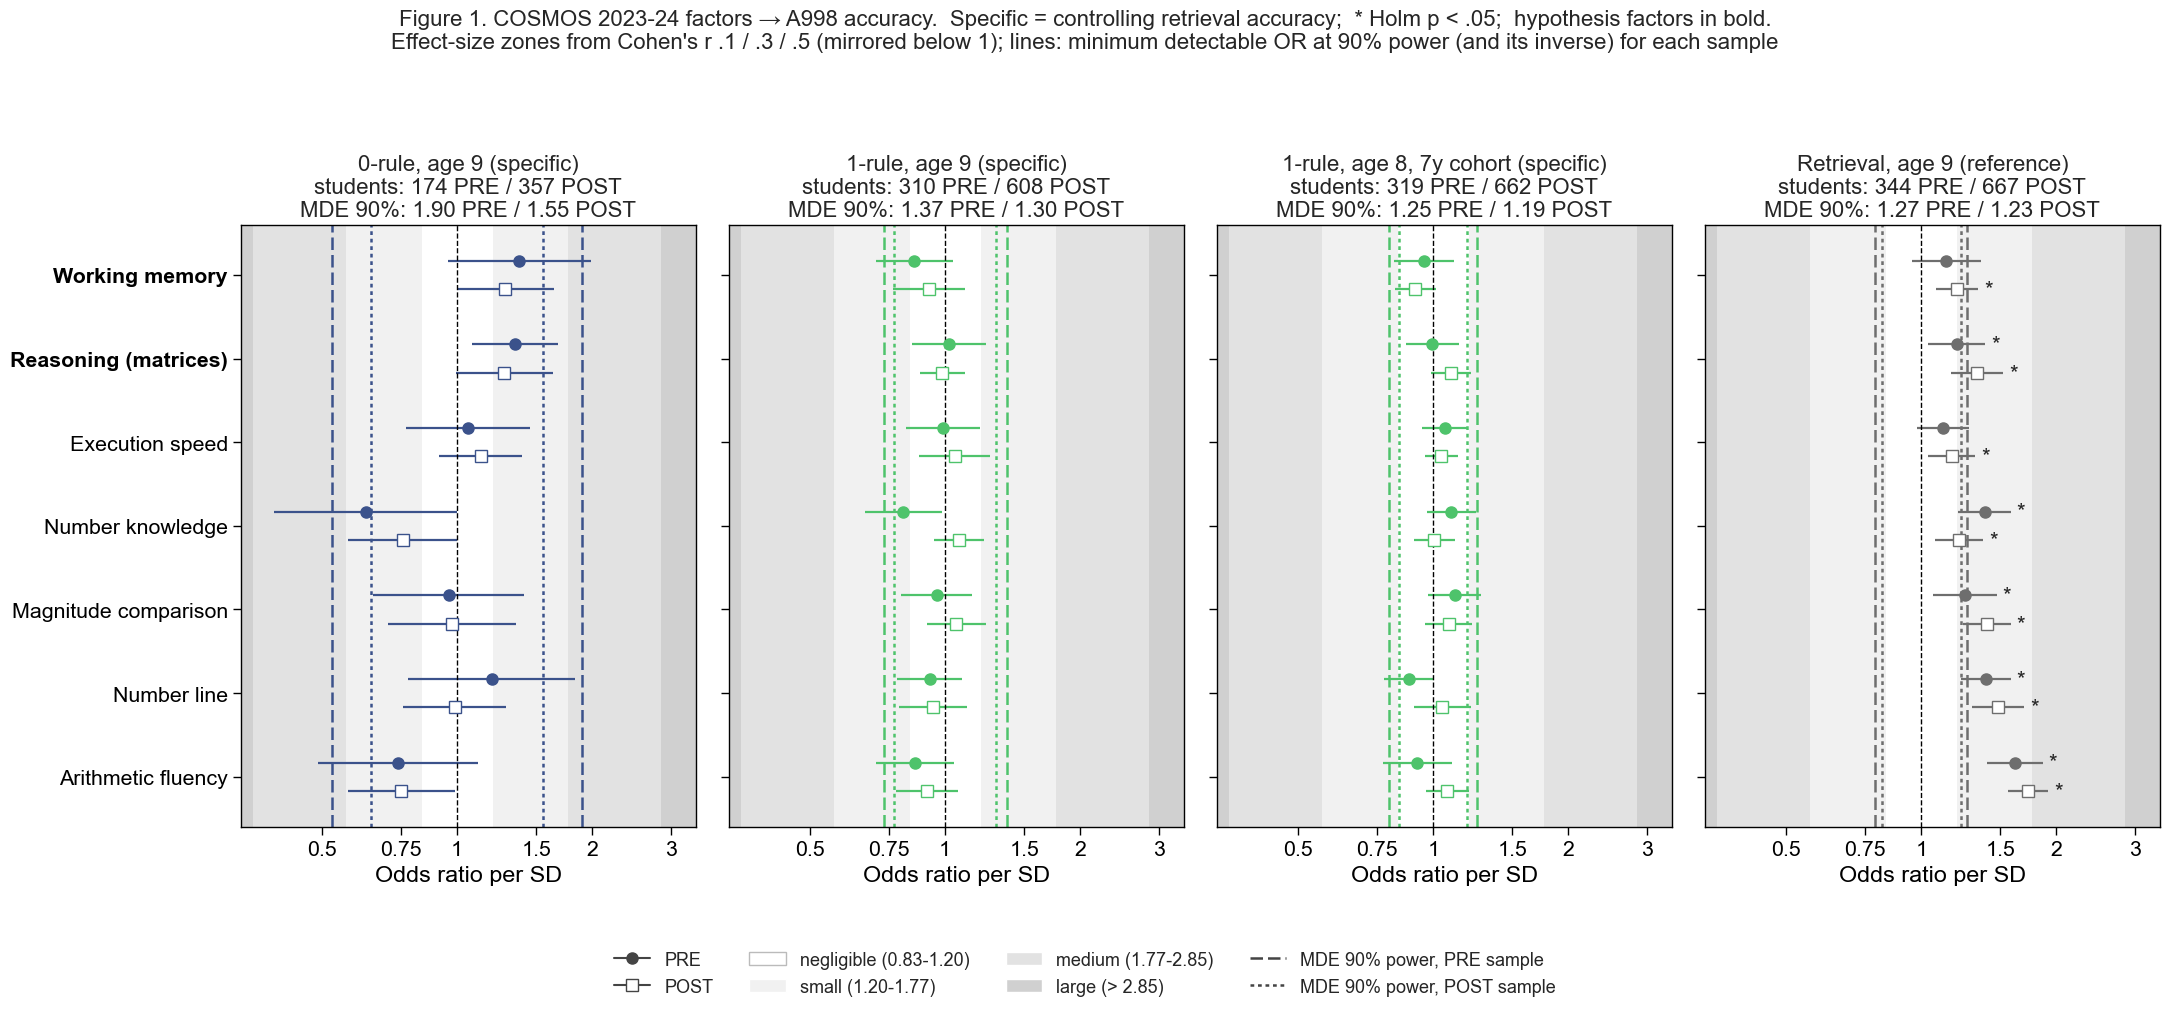

In [5]:
fig, axes = plt.subplots(1, len(PANELS), figsize=(22, 8.5), sharey=True)
for ax, lab in zip(axes, PANELS):
    sub, mde = res[res.outcome == lab], {ph: MDE90.loc[(lab, ph), "MDE_90"] for ph in ("PRE", "POST")}
    pre, post = sub[sub.phase == "PRE"], sub[sub.phase == "POST"]
    forest_panel(ax, [(pre, .17, "o", True, mde["PRE"], DASH, None), (post, -.17, "s", False, mde["POST"], DOT, None)], PCOL[lab],
                 f"{lab}\nstudents: {int(pre.n.median())} PRE / {int(post.n.median())} POST\nMDE 90%: {mde['PRE']:.2f} PRE / {mde['POST']:.2f} POST")
factor_yaxis(axes[0]); paint_it_black(axes)
fig.legend(handles=[Line2D([], [], marker="o", color="#444444", ms=8, label="PRE"),
                    Line2D([], [], marker="s", color="#444444", mfc="white", ms=8, label="POST")] + ZONE_HANDLES +
                   [mline(DASH, "MDE 90% power, PRE sample"), mline(DOT, "MDE 90% power, POST sample")],
           loc="lower center", ncol=4, frameon=False, fontsize=13, bbox_to_anchor=(.5, -.12))
fig.suptitle("Figure 1. COSMOS 2023-24 factors → A998 accuracy.  Specific = controlling retrieval accuracy;  * Holm p < .05;  "
             "hypothesis factors in bold.\nEffect-size zones from Cohen's r .1 / .3 / .5 (mirrored below 1); "
             "lines: minimum detectable OR at 90% power (and its inverse) for each sample", y=1.06, fontsize=FONT_MED)
fig.tight_layout(); save(fig, "cognitive_predictors_forest")

## 4. Is it specific to the zero rule?
(a) In the **same** 7y → age 9 students: does the factor predict 0-facts more than 1-facts (trial-level ratio)?
(b) In the **large COSMOS 2024-25 cohort** (7-year-olds at age 8 in A998 2025-26, ~22k children with 1×n): if WM or
reasoning predicted rule facts in general, this sample would show it with a tiny MDE. Retrieval is the positive control.
Different cohort and age, so a contrast, not a replication. ≈ = equivalent to negligible (TOST, 0.83-1.20).

In [6]:
t9 = trials[trials.window == W9].merge(w9[["student_uuid", "retr_logit_z", "cosmos_classroom_uuid", "country"] + ZCOLS],
                                       on="student_uuid")
both = t9.groupby("student_uuid").type.agg(lambda s: {"zero", "one"} <= set(s))
t9_both = t9[t9.student_uuid.isin(both[both].index)]
zo = pd.DataFrame([dict(phase=ph.upper(), factor=LABEL[f], **trial_interaction(t9_both, f"z_{f}_{ph}", "zero", "one"))
                   for ph in PHASES for f in FACTORS])
zo["p_holm"] = holm(zo.p.values)
print("(a) 0 vs 1, same students: ratio = OR(0-facts) / OR(1-facts)\n" +
      zo.assign(ratio_CI=zo.apply(lambda r: f"{r.ratio:.2f} [{r.lo:.2f}, {r.hi:.2f}]", axis=1))
      [["phase", "factor", "students", "OR_rule", "OR_base", "ratio_CI", "p", "p_holm"]].round(3).to_string(index=False))

print()
cnt = cached_query(Q / "a998_cosmos_student_counts.sql", cache_dir=CACHE)
NK = ["n_zero", "k_zero", "n_one", "k_one", "n_retrieval", "k_retrieval"]
big = (cnt[cnt.course_age == 8].groupby("student_uuid")
       .agg(**{c: (c, "sum") for c in NK}, a998_country=("a998_country", "first"), waves=("wave", "nunique")).reset_index()
       .merge(gold24[gold24.cosmos_course_age == 7], on="student_uuid"))
big["country"] = big.country.fillna("unknown")
big = add_retr(big)
print(f"(b) COSMOS 2024-25 7y: {(gold24.cosmos_course_age == 7).sum():,}; at age 8 in A998 2025-26: {len(big):,} "
      f"({', '.join(f'{k} {v:.0%}' for k, v in big.country.value_counts(normalize=True).head(5).items())}); "
      f"with 1×n: {(big.n_one > 0).sum():,} (median {big.loc[big.n_one > 0, 'n_one'].median():.0f} trials, "
      f"accuracy {big.k_one.sum() / big.n_one.sum():.2f}); 0-fact trials: {int(big.n_zero.sum())}")
rows = []
for lab, ft, ctl in (("1-rule, age 8 (specific)", "one", True), ("Retrieval, age 8 (reference)", "retrieval", False)):
    for ph in PH3:
        for f in FACTORS:
            rows.append(dict(outcome=lab, phase=ph.upper(), factor=f,
                             **fit_binom(big, f"z_{f}_{ph}", ft, ctl, extra=PAT if ph == "comb" else ())))
res_big = pd.DataFrame(rows)
res_big["family"] = np.where(res_big.phase == "COMB", "comb", "pre/post")
res_big["p_holm"], res_big["p_tost"] = holm_by(res_big, ["outcome", "family"]), res_big.apply(tost, axis=1)
res_big["cell"] = res_big.apply(lambda r: f"{r.OR:.2f} [{r.lo:.2f}, {r.hi:.2f}]{'*' if r.p_holm < .05 else ''}"
                                f"{'≈' if r.p_tost < .05 and r.outcome.startswith('1-rule') else ''}", axis=1)
print(f"\nOR per SD [95% CI]; * Holm p < .05 ({2 * len(FACTORS)} PRE/POST or {len(FACTORS)} COMB per outcome); ≈ equivalent to negligible (TOST p < .05)")
print(wide(res_big.assign(factor=res_big.factor.map(LABEL)), "factor", ["outcome", "phase"]).to_string())
print(res_big.groupby(["outcome", "phase"], sort=False).agg(students=("n", "median"), classrooms=("clusters", "median"), se=("se", "median"))
      .assign(MDE_90=lambda d: np.exp(Z90 * d.se)).drop(columns="se").round(2).to_string())
o23 = OUTCOMES[3][0]
cmp_ = pd.concat([res_c[res_c.outcome == o23].assign(cohort="2023-24"), res_big[(res_big.outcome == "1-rule, age 8 (specific)")
                  & (res_big.phase == "COMB")].assign(cohort="2024-25")])
cmp_["cell"] = cmp_.apply(ci_str, axis=1)
show("1-rule at age 8, combined score: the two cohorts side by side", wide(cmp_.assign(factor=cmp_.factor.map(LABEL)), "factor", "cohort"))

(a) 0 vs 1, same students: ratio = OR(0-facts) / OR(1-facts)
phase               factor  students  OR_rule  OR_base          ratio_CI     p  p_holm
  PRE       Working memory       171    1.484    0.786 1.89 [1.36, 2.63] 0.000   0.002
  PRE Reasoning (matrices)       167    1.351    0.948 1.42 [1.11, 1.82] 0.005   0.061
  PRE      Execution speed       174    0.958    1.095 0.87 [0.62, 1.23] 0.437   1.000
  PRE     Number knowledge       172    0.588    0.792 0.74 [0.41, 1.34] 0.321   1.000
  PRE Magnitude comparison       172    1.027    0.988 1.04 [0.75, 1.45] 0.820   1.000
  PRE          Number line       172    1.227    0.752 1.63 [1.05, 2.55] 0.031   0.338
  PRE   Arithmetic fluency       171    0.726    0.793 0.92 [0.63, 1.33] 0.642   1.000
 POST       Working memory       358    1.317    0.969 1.36 [1.02, 1.81] 0.035   0.351
 POST Reasoning (matrices)       356    1.289    1.058 1.22 [0.92, 1.62] 0.171   1.000
 POST      Execution speed       358    1.007    1.128 0.89 [0.72, 1.

### Figure 2. Zero rule vs one rule (combined score)
**A** is the zero-rule result of Figure 1 with the combined score. **B** is the same model for the one rule in the large
2024-25 cohort: estimates hug 1 with tight intervals (a precise null, not a lack of power, MDE ≈ 1.05). **C** shows the
same factors and data do predict ordinary facts, so B is not a measurement failure. Unlike Figure 1, B and C are a
different, 60× larger cohort.

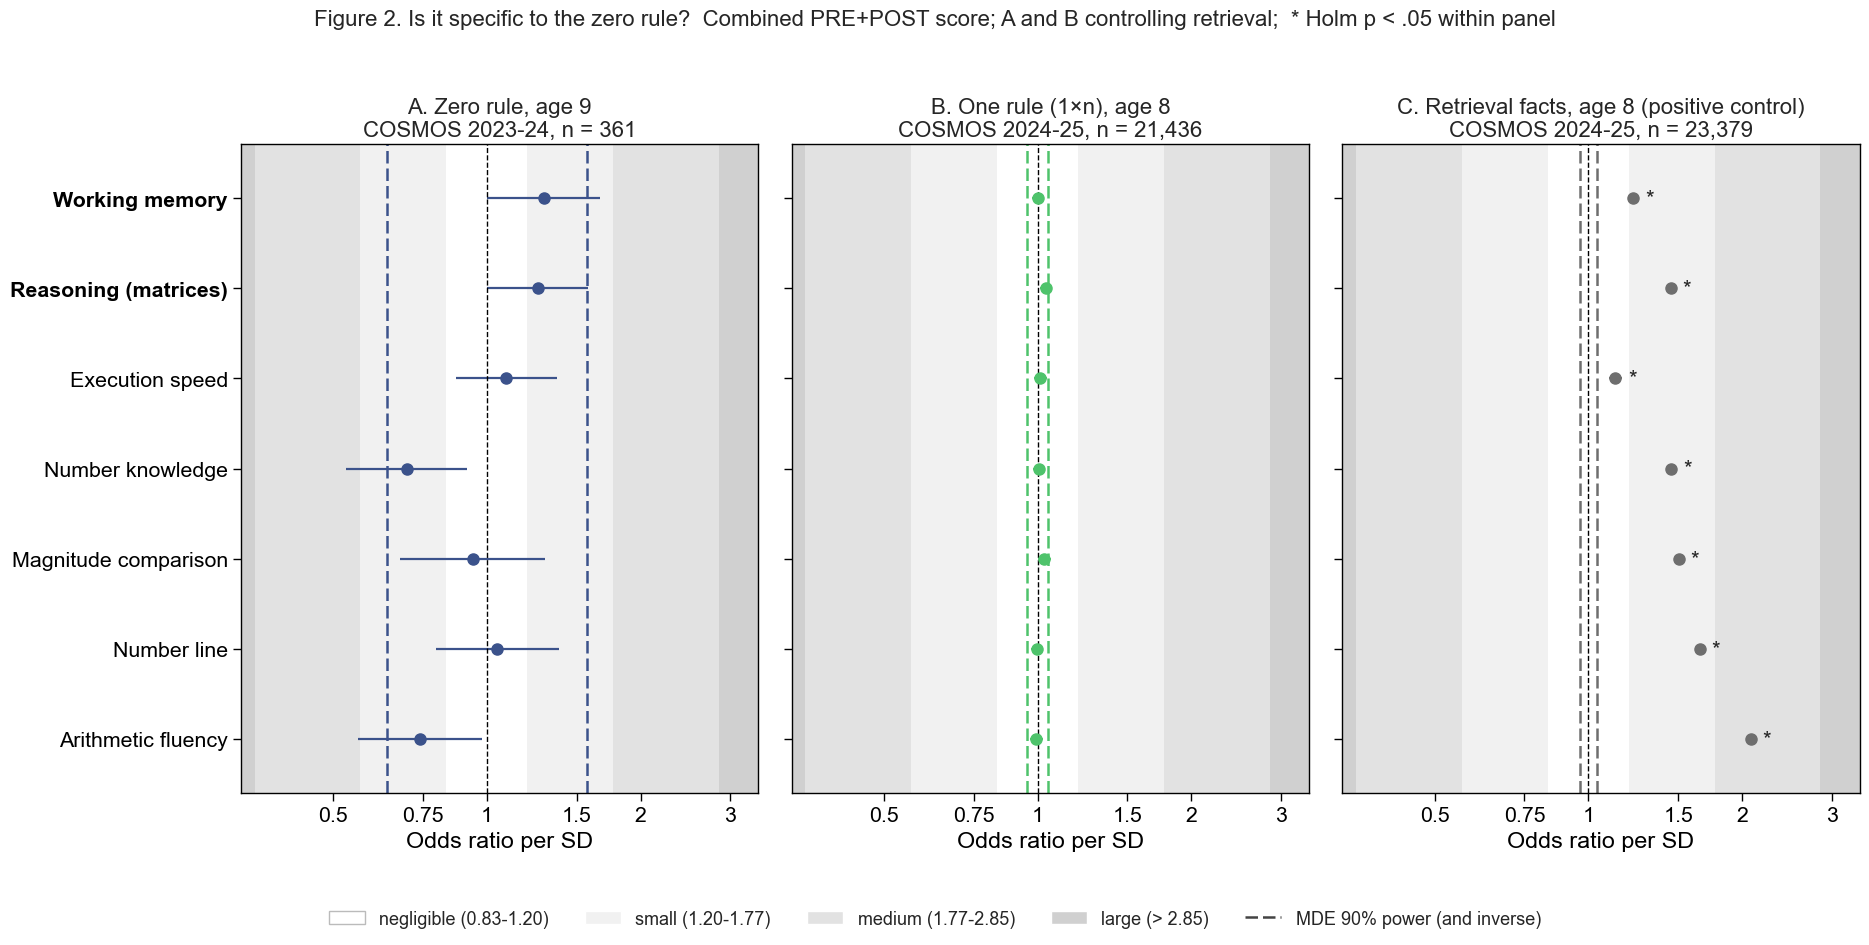

In [7]:
big_c = res_big[res_big.phase == "COMB"]
b1, br, z0 = big_c[big_c.outcome.str.startswith("1-rule")], big_c[big_c.outcome.str.startswith("Retr")], res_c[res_c.outcome == PANELS[0]]
fig, axes = plt.subplots(1, 3, figsize=(19, 8.5), sharey=True)
for ax, (sub, col, ttl) in zip(axes, (
        (z0, C_ZERO, f"A. Zero rule, age 9\nCOSMOS 2023-24, n = {int(z0.n.median())}"),
        (b1, C_ONE, f"B. One rule (1×n), age 8\nCOSMOS 2024-25, n = {int(b1.n.median()):,}"),
        (br, "#6E6E6E", f"C. Retrieval facts, age 8 (positive control)\nCOSMOS 2024-25, n = {int(br.n.median()):,}"))):
    forest_panel(ax, [(sub, 0, "o", True, float(np.exp(Z90 * sub.se.median())), DASH, None)], col, ttl)
factor_yaxis(axes[0]); paint_it_black(axes)
fig.legend(handles=ZONE_HANDLES + [mline(DASH, "MDE 90% power (and inverse)")], loc="lower center", ncol=5, frameon=False,
           fontsize=13, bbox_to_anchor=(.5, -.08))
fig.suptitle("Figure 2. Is it specific to the zero rule?  Combined PRE+POST score; A and B controlling retrieval;  "
             "* Holm p < .05 within panel", y=1.02, fontsize=FONT_MED)
fig.tight_layout(); save(fig, "cognitive_predictors_forest_comb_contrast")

## 5. Working memory or reasoning?
Both on one common sample (alone vs together), then all 7 factors together. WM and reasoning correlate only ρ ≈ .3-.4,
and each keeps ≈ 75% of its effect when the other is added (expected 1/(1 + ρ)): both contribute, the data cannot rank them.

In [8]:
rows = []
for ph in PHASES:
    wm, rs = f"z_working_memory_{ph}", f"z_reasoning_{ph}"
    common = w9.dropna(subset=[wm, rs])
    for name, cols in (("WM alone", [wm]), ("reasoning alone", [rs]), ("WM + reasoning", [wm, rs])):
        rows += [dict(phase=ph.upper(), model=name, **r) for r in fit_many(common, cols)]
    rho = common[common.n_zero > 0][[wm, rs]].corr("spearman").iloc[0, 1]
    rows[-1]["model"] += f" (ρ = {rho:.2f})"
d4 = pd.DataFrame(rows)
print("WM vs reasoning on one common sample\n" + d4.assign(OR_CI=d4.apply(ci_str, axis=1))[["phase", "model", "factor", "n", "OR_CI", "p"]]
      .round(3).to_string(index=False))
joint = {}
for ft in ("zero", "one"):
    for ph in PHASES:
        jj = pd.DataFrame(fit_many(w9, [f"z_{f}_{ph}" for f in FACTORS], ft))
        joint[f"{ft} {ph.upper()} (n={jj.n.iloc[0]})"] = jj.set_index("factor").apply(
            lambda r: f"{r.OR:.2f}{'*' if r.p < .05 else ''}", axis=1)
print(f"\nAll {len(FACTORS)} factors together, OR per SD (* p < .05), age 9 (suppressors: do not interpret the split)\n" + pd.DataFrame(joint).to_string())

WM vs reasoning on one common sample
phase                     model               factor   n             OR_CI     p
  PRE                  WM alone       Working memory 168 1.32 [0.92, 1.90] 0.132
  PRE           reasoning alone Reasoning (matrices) 168 1.35 [1.08, 1.68] 0.009
  PRE            WM + reasoning       Working memory 168 1.24 [0.84, 1.81] 0.277
  PRE WM + reasoning (ρ = 0.31) Reasoning (matrices) 168 1.28 [1.02, 1.62] 0.033
 POST                  WM alone       Working memory 354 1.27 [0.99, 1.64] 0.063
 POST           reasoning alone Reasoning (matrices) 354 1.27 [0.99, 1.64] 0.059
 POST            WM + reasoning       Working memory 354 1.19 [0.90, 1.58] 0.217
 POST WM + reasoning (ρ = 0.38) Reasoning (matrices) 354 1.20 [0.91, 1.58] 0.209

All 7 factors together, OR per SD (* p < .05), age 9 (suppressors: do not interpret the split)
                     zero PRE (n=168) zero POST (n=343) one PRE (n=298) one POST (n=587)
factor                                           

## 6. Robustness (7y → age 9)
(a) Trial level, rule vs retrieval trials. (b) All 0-facts right (≥ 2 trials). (c) Any "n×0 = n" error. (d) Mexico only vs
Spain + US. (e) Formal factor × Mexico test. (f) Without the 1.2 s fast-wrong filter, and whether fast-wrong answers
reflect disengagement.

In [9]:
ti = pd.DataFrame([dict(rule=rule, phase=ph.upper(), factor=LABEL[f], **trial_interaction(t9, f"z_{f}_{ph}", rule, "retrieval"))
                   for ph in PHASES for f in FACTORS for rule in ("zero", "one")])
ti["p_holm"] = holm_by(ti, "rule")
ti["cell"] = ti.apply(lambda r: f"{r.ratio:.2f} [{r.lo:.2f}, {r.hi:.2f}]{'*' if r.p_holm < .05 else ''}", axis=1)
w9z = w9[(w9.n_zero > 0) & (w9.n_retrieval >= MIN_RETR)].copy()
w9z["all_right"], w9z["any_copy"] = (w9z.k_zero == w9z.n_zero).astype(int), (w9z.copy_zero > 0).astype(int)
rb = pd.DataFrame([dict(test=t, phase=ph.upper(), factor=LABEL[f], **fit_logit(d_, y_, f"z_{f}_{ph}"))
                   for ph in PHASES for f in FACTORS
                   for t, d_, y_ in (("(b) all right", w9z[w9z.n_zero >= 2], "all_right"), ("(c) any n×0=n", w9z, "any_copy"))])
rb["p_holm"] = holm_by(rb, "test")
rb["cell"] = rb.apply(ci_str, star_col="p_holm", axis=1)
rob = pd.concat([wide(ti, ["phase", "factor"], "rule").rename(columns=lambda c: f"(a) {c} trials"), wide(rb, ["phase", "factor"], "test")], axis=1)
print(rob.to_string())
print(f"'n×0 = n' share of 0-fact errors: {w9z.copy_zero.sum() / (w9z.n_zero - w9z.k_zero).sum():.1%}")
sens = pd.DataFrame([dict(subset=sub_, outcome=lab, phase=ph.upper(), factor=LABEL[f],
                          **fit_binom(d_[d_.window == W9], f"z_{f}_{ph}", ft, True))
                     for sub_, d_ in (("MX only", stud[stud.country == "MX"]), ("ES + US", stud[stud.country != "MX"]))
                     for ph in PHASES for f in HYP for lab, ft in (("0-rule", "zero"), ("1-rule", "one"))])
sens.loc[sens.clusters < 10, ["OR", "lo", "hi", "p"]] = np.nan
print("\n(d) Mexico only vs Spain + US (fits with < 10 classrooms blanked)\n" + sens.drop(columns="se").round(3).to_string(index=False))

rows = []
for ph in PH3:
    for f in HYP:
        z = f"z_{f}_{ph}"
        d_ = w9.assign(zxmx=w9[z] * (w9.country == "MX"))
        rows.append(dict(phase=ph.upper(), factor=LABEL[f], **fit_binom(d_, z, "zero", True, term="zxmx",
                                                                         extra=["zxmx"] + (PAT if ph == "comb" else []))))
mx = pd.DataFrame(rows)
mx["rest_classrooms"] = [w9.loc[(w9.country != "MX") & w9[f"z_{f}_{ph}"].notna() & (w9.n_zero > 0) & (w9.n_retrieval >= MIN_RETR),
                                 "cosmos_classroom_uuid"].nunique() for ph in PH3 for f in HYP]
mx.loc[mx.rest_classrooms < 10, ["OR", "lo", "hi", "p"]] = np.nan          # same rule as 5(d): < 10 classrooms not reported
mx["p_holm"] = np.nan; ok = mx.p.notna(); mx.loc[ok, "p_holm"] = holm(mx.loc[ok, "p"].values)
print("\n(e) Factor × Mexico interaction: ratio = OR in Mexico / OR elsewhere (< 10 classrooms outside MX blanked)\n" + mx.assign(ratio_CI=mx.apply(lambda r: ci_str(r) if r.OR == r.OR else "-", axis=1))
      [["phase", "factor", "n", "clusters", "rest_classrooms", "ratio_CI", "p", "p_holm"]]
      .round(3).to_string(index=False))

                               (a) zero trials     (a) one trials      (b) all right       (c) any n×0=n
phase factor                                                                                            
PRE   Working memory         1.59 [1.14, 2.22]  0.84 [0.70, 1.02]  1.25 [0.79, 1.99]   0.67 [0.45, 0.98]
      Reasoning (matrices)  1.39 [1.12, 1.72]*  1.02 [0.84, 1.23]  1.47 [1.12, 1.93]   0.80 [0.59, 1.09]
      Execution speed        0.92 [0.67, 1.26]  0.98 [0.82, 1.16]  1.05 [0.76, 1.45]   1.25 [0.95, 1.65]
      Number knowledge       0.66 [0.40, 1.07]  0.82 [0.68, 1.00]  0.75 [0.47, 1.21]   1.24 [0.77, 2.01]
      Magnitude comparison   1.11 [0.79, 1.57]  0.96 [0.81, 1.13]  1.04 [0.63, 1.71]   0.77 [0.56, 1.05]
      Number line            1.22 [0.84, 1.79]  0.91 [0.77, 1.08]  0.94 [0.59, 1.49]   1.01 [0.74, 1.40]
      Arithmetic fluency     0.82 [0.56, 1.21]  0.87 [0.72, 1.05]  0.84 [0.45, 1.59]  1.59 [1.18, 2.14]*
POST  Working memory         1.39 [1.08, 1.78]  0.92 [0

In [10]:
fw = trials_all.dropna(subset=["window"]).merge(gold[["student_uuid", "country"]], on="student_uuid")
fz = fw[(fw.type == "zero") & fw.fast_wrong.astype(bool)]
print("(f) Without the 1.2 s filter\nFast-wrong share by window × type:\n" + fw.pivot_table(index="window", columns="type", values="fast_wrong", aggfunc="mean").round(3).to_string())
print("by country (age 9):\n" + fw[fw.window == W9].pivot_table(index="country", columns="type", values="fast_wrong", aggfunc="mean").round(3).to_string())
print(f"Fast-wrong 0-fact answers: {len(fz)}, median RT {fz.rt_seconds.median():.2f} s, answer = n {(fz.answer == fz.left_factor + fz.right_factor).mean():.0%}")
stud_nf = make_stud(trials_all)
res_nf = pd.DataFrame([dict(outcome=lab, phase=ph.upper(), factor=f, **fit_binom(stud_nf[stud_nf.window == w], f"z_{f}_{ph}", ft, ctl))
                       for lab, w, ft, ctl in OUTCOMES for ph in PHASES for f in FACTORS])
res_nf["p_holm"], mde_nf = holm_by(res_nf, "outcome"), mde_tab(res_nf, ["outcome", "phase"])
cmp_ = res.merge(res_nf, on=["outcome", "phase", "factor"], suffixes=("", "_nf"))
cmp_ = cmp_[cmp_.outcome == PANELS[0]]
print(f"\n0-rule specific, filtered vs no filter (* Holm-{2 * len(FACTORS)} p < .05)\n" + pd.DataFrame({
    "phase": cmp_.phase, "factor": cmp_.factor.map(LABEL), "n": cmp_.n, "filtered": cmp_.apply(ci_str, star_col="p_holm", axis=1),
    "n_nf": cmp_.n_nf, "no filter": cmp_.apply(lambda r: f"{r.OR_nf:.2f} [{r.lo_nf:.2f}, {r.hi_nf:.2f}]{'*' if r.p_holm_nf < .05 else ''}", axis=1)
}).to_string(index=False))
print("\nMDE 90%:\n" + MDE90[["students", "MDE_90"]].join(mde_nf[["students", "MDE_90"]], rsuffix="_nf").loc[PANELS].round(2).to_string())
fwr = trials_all[trials_all.window == W9].groupby("student_uuid").agg(n_fw=("fast_wrong", "sum"), n_tot=("fast_wrong", "size")).reset_index()
s9 = stud_nf[stud_nf.window == W9].merge(fwr.assign(n_fw=fwr.n_fw.astype(int)), on="student_uuid")
s9["fw_rate_z"] = np.log((s9.n_fw + .5) / (s9.n_tot - s9.n_fw + .5)); s9["fw_rate_z"] = (s9.fw_rate_z - s9.fw_rate_z.mean()) / s9.fw_rate_z.std()
rows = []
for ph in PHASES:
    for f in HYP:
        z, d_ = f"z_{f}_{ph}", s9.dropna(subset=[f"z_{f}_{ph}"])
        rows.append(dict(test="fast-wrong rate ~ factor", phase=ph.upper(), factor=LABEL[f],
                         **or_row(glm(np.column_stack([d_.n_fw, d_.n_tot - d_.n_fw]), design(d_, z, False), d_), "z", d_)))
        d_ = s9[(s9.n_zero > 0) & (s9.n_retrieval >= MIN_RETR)].dropna(subset=[z])
        X = design(d_, z, True); X["fw"] = d_.fw_rate_z
        rows.append(dict(test="0-rule, no filter, + fast-wrong rate", phase=ph.upper(), factor=LABEL[f],
                         **or_row(glm(np.column_stack([d_.k_zero, d_.n_zero - d_.k_zero]), X, d_), "z", d_)))
eng = pd.DataFrame(rows)
print("\nEngagement check\n" + eng.assign(OR_CI=eng.apply(ci_str, axis=1))[["test", "phase", "factor", "n", "OR_CI", "p"]].round(3).to_string(index=False))

(f) Without the 1.2 s filter
Fast-wrong share by window × type:
type          one  retrieval   zero
window                             
6y → age 8  0.381      0.391    NaN
7y → age 8  0.412      0.440    NaN
7y → age 9  0.267      0.268  0.274
by country (age 9):
type       one  retrieval   zero
country                         
ES       0.172      0.179  0.153
MX       0.358      0.352  0.387
US       0.109      0.117  0.088
Fast-wrong 0-fact answers: 290, median RT 0.80 s, answer = n 11%

0-rule specific, filtered vs no filter (* Holm-14 p < .05)
phase               factor   n          filtered  n_nf          no filter
  PRE       Working memory 173 1.38 [0.95, 1.99]   184  1.27 [0.92, 1.77]
  PRE Reasoning (matrices) 168 1.35 [1.08, 1.68]   179 1.56 [1.20, 2.02]*
  PRE      Execution speed 176 1.06 [0.77, 1.45]   188  1.17 [0.86, 1.60]
  PRE     Number knowledge 174 0.63 [0.39, 1.00]   186  0.82 [0.60, 1.12]
  PRE Magnitude comparison 174 0.96 [0.65, 1.41]   186  1.21 [0.91, 1.60]
  

## 7. Selection bias: does who ends up in the sample explain the effect? (#60)
Only the 7-year-olds whose school ran A998 at age 9 in T3 (A998 is opt-in per school) AND who drew ≥ 1 0-fact (each
student gets a random subset of facts) enter the zero-rule models. Checks: (a) funnel and balance against the whole
cohort; (b) is drawing a 0-fact, given a T3 test, explained by test length alone (missing at random)? (c) inverse-
probability-of-selection weights from everything COSMOS measured (7 combined factors, country, measurement pattern),
re-weighting the analysed students to the 844-student cohort, CI by classroom bootstrap that re-fits the weights;
(d) COSMOS-classroom fixed effects: the within-classroom
estimate removes school-level selection and school-level confounding. Selection on the predictor itself does not bias
the slope; selection on unmeasured, outcome-related traits is not removed by any of these.

In [11]:
coh = gold[gold.cosmos_course_age == 7].copy()
t9w = trials[(trials.cosmos_course_age == 7) & (trials.course_age == 9)]
t3 = t9w[pd.to_datetime(t9w.response_at).dt.month.isin([5, 6, 7, 8])]
ana = set(w9.loc[(w9.n_zero > 0) & (w9.n_retrieval >= MIN_RETR), "student_uuid"])
print("(a) funnel\n" + pd.Series({
    "COSMOS 2023-24, 7y": len(coh), "any A998 response": coh.student_uuid.isin(trials_all.student_uuid).sum(),
    "A998 at age 9": coh.student_uuid.isin(t9w.student_uuid).sum(), "A998 at age 9, T3": coh.student_uuid.isin(t3.student_uuid).sum(),
    "≥ 1 0-fact (kept)": coh.student_uuid.isin(w9.loc[w9.n_zero > 0, "student_uuid"]).sum(),
    f"+ ≥ {MIN_RETR} retrieval = analysed": len(ana)}).to_string())
coh["sel"], coh["m_any"] = coh.student_uuid.isin(ana).astype(int), coh[[f"z_{f}_comb" for f in FACTORS]].isna().any(axis=1).astype(float)
coh = coh.assign(**{f"x_{f}": coh[f"z_{f}_comb"].fillna(0) for f in FACTORS})
coh = coh.join(pd.get_dummies(coh.country, prefix="cty", drop_first=True, dtype=float))
SEL_COVS = [f"x_{f}" for f in FACTORS] + ["m_any"] + [c for c in coh if c.startswith("cty_")] + PAT
wsel, auc = ipw(coh, "sel", SEL_COVS)
coh["w"], s_ = wsel.reindex(coh.index), coh.sel.astype(bool).values
bal = pd.DataFrame({"unweighted": [smd_to_cohort(coh[c].values, s_) for c in SEL_COVS],
                    "IPW": [smd_to_cohort(coh[c].values, s_, coh.w[s_].values) for c in SEL_COVS]},
                   index=[LABEL.get(c[2:], {"m_any": "any factor missing", "cty_MX": "Mexico", "cty_US": "United States",
                          "pat_pre_only": "PRE only", "pat_post_only": "POST only"}.get(c, c)) for c in SEL_COVS])
ess = wsel.sum() ** 2 / (wsel ** 2).sum()
print(f"\nSelection model AUC {auc:.2f}; weights {wsel.min():.2f}-{wsel.max():.2f} (truncated 1-99%), ESS {ess:.0f} of {len(wsel)}")
print("SMD selected - cohort\n" + bal.round(2).to_string())
t3s = (t3.groupby("student_uuid").agg(n_t3=("correct", "size"), has0=("type", lambda s: int((s == "zero").any())))
       .reset_index().merge(coh, on="student_uuid"))
t3s["log_n"] = np.log(t3s.n_t3)
rows = []
for f in HYP:
    d_ = t3s.dropna(subset=[f"z_{f}_comb"])
    m_ = glm(d_.has0, design(d_, f"z_{f}_comb", False, extra=["log_n"] + PAT), d_)
    rows.append(dict(factor=LABEL[f], n=len(d_), drew_0=int(d_.has0.sum()), **{"OR factor": np.exp(m_.params["z"]),
                "p factor": m_.pvalues["z"], "OR log test length": np.exp(m_.params["log_n"]), "p length": m_.pvalues["log_n"]}))
print("\n(b) P(≥ 1 0-fact | A998 T3 at age 9) ~ factor (comb) + log test length + country + pattern\n"
      + pd.DataFrame(rows).round(3).to_string(index=False))
w9w = w9.merge(coh[["student_uuid", "w"]], on="student_uuid", how="left")
SPECS = {(lab, ph.upper(), LABEL[f]): (f"z_{f}_{ph}", "zero", ctl, PAT if ph == "comb" else ())
         for lab, ctl in (("0-rule specific", True), ("0-rule raw", False)) for ph in PH3 for f in HYP}
rows = []
for (lab, ph, fl), (z, ft, ctl, extra) in SPECS.items():
    for est, kw in (("complete case (main)", {}), ("classroom FE", dict(fe="cosmos_classroom_uuid"))):
        rows.append(dict(estimator=est, outcome=lab, phase=ph, factor=fl, **fit_binom(w9w, z, ft, ctl, extra=extra, **kw)))
    r_ = fit_binom(w9w.dropna(subset=["w"]), z, ft, ctl, w="w", extra=extra)
    rows.append(dict(estimator="IPW", outcome=lab, phase=ph, factor=fl, **r_))
bt = boot_ipw(coh, w9w, SPECS, SEL_COVS)
selr = pd.DataFrame(rows)
for (lab, ph, fl), b_ in bt.items():                       # IPW: point estimate from the full sample, CI / p from the bootstrap
    i = selr.index[(selr.estimator == "IPW") & (selr.outcome == lab) & (selr.phase == ph) & (selr.factor == fl)][0]
    selr.loc[i, ["lo", "hi"]] = np.exp(np.quantile(b_, [.025, .975]))
    selr.loc[i, "p"] = min(1, 2 * min((b_ <= 0).mean(), (b_ >= 0).mean()))
    selr.loc[i, "se"] = b_.std()
selr["cell"] = selr.apply(lambda r: f"{r.OR:.2f} [{r.lo:.2f}, {r.hi:.2f}]{'*' if r.p < .05 else ''}", axis=1)
print("\n(c)-(d) zero rule, OR per SD [95% CI], * p < .05 (unadjusted; Holm in sections 3-4). IPW CI: 500 classroom bootstraps\n"
      + wide(selr, ["outcome", "phase", "factor"], "estimator")[["complete case (main)", "IPW", "classroom FE"]].to_string())
print(selr.groupby("estimator", sort=False).agg(students=("n", "median"), classrooms=("clusters", "median")).astype(int).T.to_string())

(a) funnel
COSMOS 2023-24, 7y            844
any A998 response             800
A998 at age 9                 685
A998 at age 9, T3             488
≥ 1 0-fact (kept)             375
+ ≥ 5 retrieval = analysed    365

Selection model AUC 0.66; weights 0.55-2.18 (truncated 1-99%), ESS 332 of 365
SMD selected - cohort
                      unweighted   IPW
Working memory              0.03 -0.03
Reasoning (matrices)        0.11 -0.01
Execution speed            -0.09  0.00
Number knowledge            0.07 -0.00
Magnitude comparison        0.15 -0.02
Number line                 0.16  0.00
Arithmetic fluency          0.19 -0.04
any factor missing          0.02  0.00
Mexico                     -0.14  0.01
United States               0.19 -0.01
PRE only                   -0.12 -0.08
POST only                   0.05  0.01

(b) P(≥ 1 0-fact | A998 T3 at age 9) ~ factor (comb) + log test length + country + pattern
              factor   n  drew_0  OR factor  p factor  OR log test length  p length
 

### Figure 3. Selection and estimator robustness
**A** compares the analysed children with the whole 7y cohort on everything COSMOS measured, before (grey) and after
(blue) inverse-probability weighting: within the dotted ±0.10 lines = balanced. **B** puts the zero-rule estimate for WM
and reasoning (combined score) side by side under the main model, IPW, within-classroom fixed effects and without the
1.2 s filter: if selection or the filter drove the result, the estimates would move towards 1.

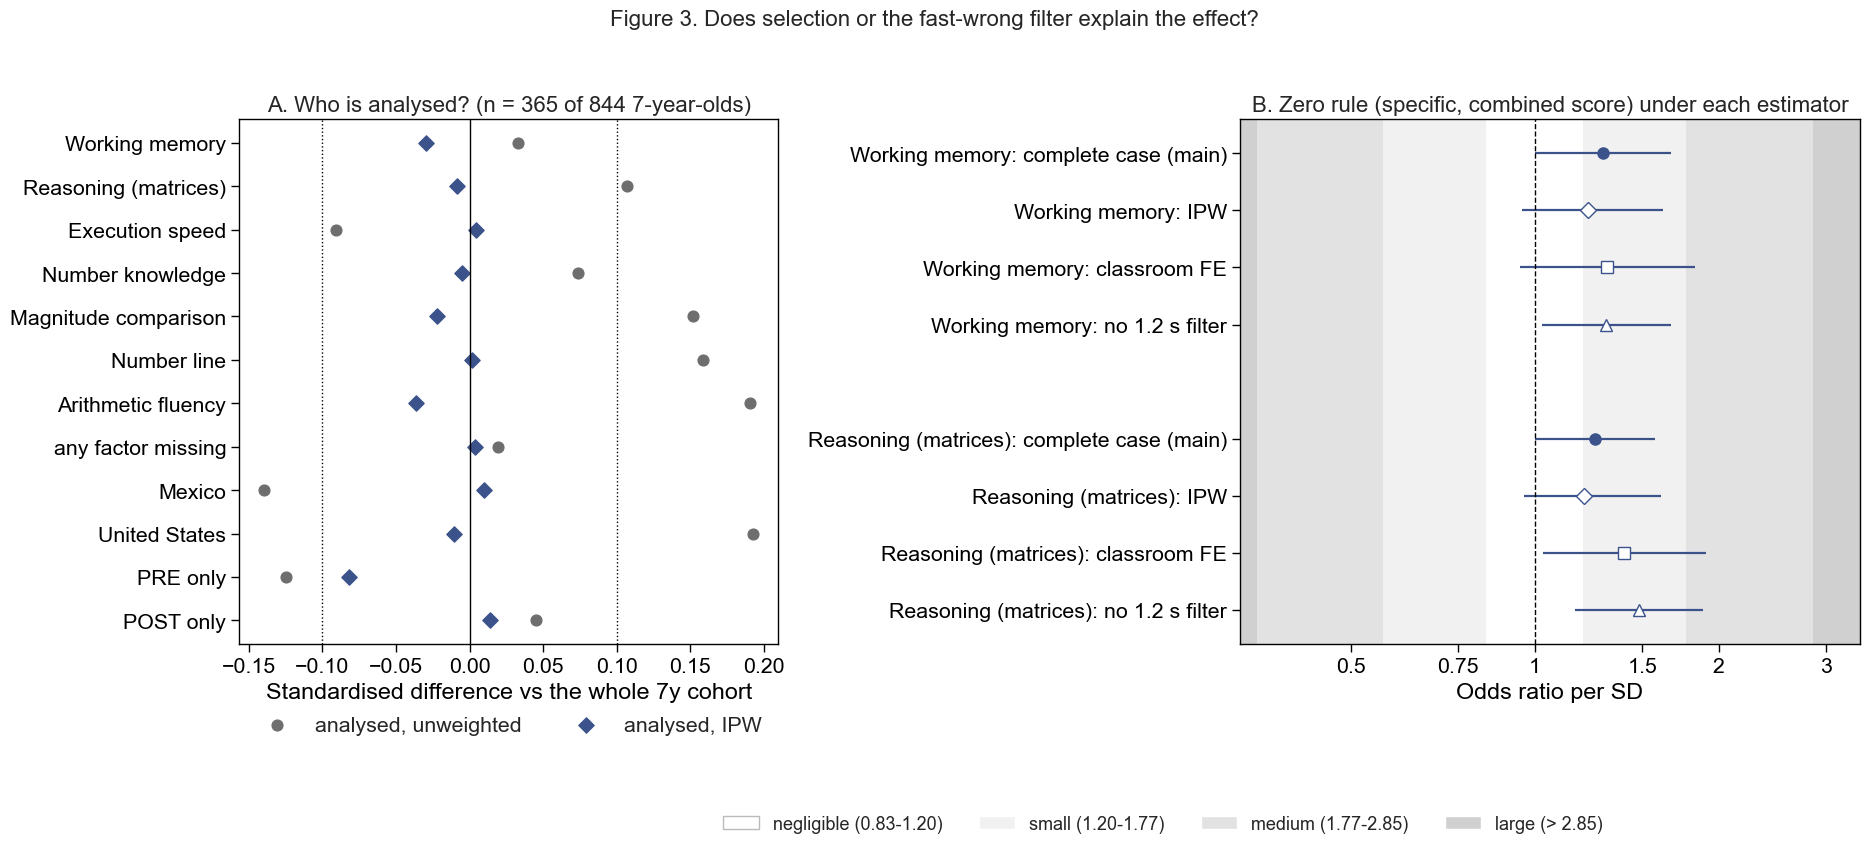

In [12]:
nf = {f: fit_binom(stud_nf[stud_nf.window == W9], f"z_{f}_comb", "zero", True, extra=PAT) for f in HYP}    # no 1.2 s filter
EST = ["complete case (main)", "IPW", "classroom FE", "no 1.2 s filter"]
MK = {"complete case (main)": ("o", True), "IPW": ("D", False), "classroom FE": ("s", False), "no 1.2 s filter": ("^", False)}
pick = lambda f, e: nf[f] if e == "no 1.2 s filter" else selr[(selr.estimator == e) & (selr.outcome == "0-rule specific")
                                                           & (selr.phase == "COMB") & (selr.factor == LABEL[f])].iloc[0]
fig, (axa, axb) = plt.subplots(1, 2, figsize=(19, 7.5), gridspec_kw={"width_ratios": [1, 1.15]})
yy = np.arange(len(bal))[::-1]
axa.scatter(bal.unweighted, yy, color="#6E6E6E", s=60, label="analysed, unweighted")
axa.scatter(bal.IPW, yy, color=C_ZERO, s=60, marker="D", label="analysed, IPW")
for v, ls_ in ((-.1, ":"), (.1, ":"), (0, "-")):
    axa.axvline(v, color="black", lw=1, ls=ls_)
axa.set_yticks(yy); axa.set_yticklabels(bal.index); axa.set_xlabel("Standardised difference vs the whole 7y cohort")
axa.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.1), ncol=2)
axa.set_title(f"A. Who is analysed? (n = {len(ana)} of {len(coh)} 7-year-olds)", fontsize=FONT_MED)
ylab = []
for g, f in enumerate(HYP):
    for k, e in enumerate(EST):
        r, y = pick(f, e), -(g * (len(EST) + 1) + k)
        axb.errorbar(r["OR"], y, xerr=[[r["OR"] - r["lo"]], [r["hi"] - r["OR"]]], fmt=MK[e][0], color=C_ZERO, ms=8, lw=1.6,
                     mfc=C_ZERO if MK[e][1] else "white")
        ylab.append((y, f"{LABEL[f]}: {e}"))
or_axis(axb); axb.set_ylim(min(y for y, _ in ylab) - .6, .6)
axb.set_yticks([y for y, _ in ylab]); axb.set_yticklabels([l for _, l in ylab])
axb.set_title("B. Zero rule (specific, combined score) under each estimator", fontsize=FONT_MED)
paint_it_black([axa, axb])
fig.legend(handles=ZONE_HANDLES, loc="lower center", ncol=4, frameon=False, fontsize=13, bbox_to_anchor=(.62, -.1))
fig.suptitle("Figure 3. Does selection or the fast-wrong filter explain the effect?", y=1.02, fontsize=FONT_MED)
fig.tight_layout(); save(fig, "cognitive_predictors_robustness")

## 8. Conclusions

**Sample.** COSMOS 2023-24, 7 factors (processing speed excluded). Of 844 7-year-olds, 365 have a 0-fact at age 9
(≈ 2 trials each), so the zero-rule models can only detect OR ≳ 1.55 per SD (90% power, POST).

1. **WM and reasoning predict the zero rule (§3, Figure 1).** OR 1.26-1.38 per SD, ≈ 0.13-0.18 latent SD.
   Only reasoning PRE survives Holm-4 (1.35 [1.08, 1.68], p = .035); combined score 1.29 / 1.26 (Holm-2 p = .095).
2. **It is specific to the zero rule (§4, Figure 2).** In the same students WM predicts 0-facts more than 1-facts
   (ratio 1.89, Holm p = .002). In the 2024-25 cohort (21,809 children) every factor gives OR 0.99-1.04 for 1×n, a
   precise null, while the same factors predict retrieval strongly (1.11-2.08).
3. **WM and reasoning both contribute; the data cannot rank them (§5).** They correlate only ρ .31-.38 and each keeps
   ≈ 75% of its effect when entered together. Domain-specific factors predict retrieval, not the rule.
4. **The result is robust (§6-7, Figure 3).** Same direction at trial level, with an all-or-nothing outcome and without
   the 1.2 s filter (reasoning 1.49-1.56). Selection is modest (|SMD| ≤ .19): IPW lowers the ORs by 4-7% (1.20-1.28,
   CIs include 1) and within-classroom estimates are larger (reasoning 1.40-1.59). The Mexico concentration is not a
   significant difference (p = .59).

**Bottom line.** A modest, zero-rule-specific effect of WM and reasoning that is consistent across methods but not yet
confirmed: confirmatory significance is fragile and this sample only detects larger effects.

**Next.** Replicate with COSMOS 2024-25 (≈ 10k children expected with a 0-fact) in the T3 2026-27 wave, with this
specification fixed in advance; add RT and the order effect.